# Flagging Tutorial

_How mission flagging worked and how to interpret new flag backplanes._

In [1]:
import numpy as np                # for scientific computing, good for working with large arrays  
import pandas as pd               # for data analysis, has easy to work with data frames 
import matplotlib.pyplot as plt   # for plotting 
from astropy.io import fits       # for reading / writing / manipulating FITS files 

### Mission Bad Detector Element Maps

The original mission files have flag backplanes they call bad detector element maps (BDE) that are generated from dark signal observations. These files have the same orientation and number of bands & samples as the L0 data, but not the L1B data. They are provided in the USGS PDS as files ending in '_bde.fits'. These BDE maps are in detector POV, where the x-axis is samples (cross-track) and y-axis bands / channels. 

__As part of calibration, flagged pixels in the BDE maps were linearly spectrally interpolated. This means values at the interpolated pixels are not 
true observational data.__

Here is an example BDE map from the mission. 

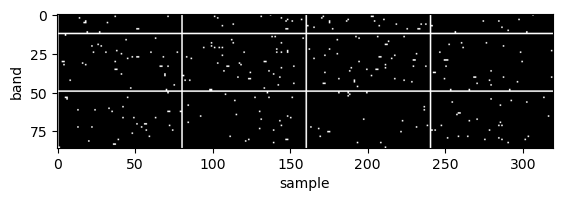

In [2]:
path_to_bde = "./tutorial_data/m3g20090420t201515_bde.fits"
with fits.open(path_to_bde) as hdul: 
    bde = hdul[0].data

# the BDE maps have different values for different flags, but anything over 0 was flagged and spectrally interpolated
plt.imshow(bde>0, cmap='grey')
plt.xlabel('sample')
plt.ylabel('band')
plt.show()

The BDE maps have more bands and samples than L1B and L2 data. 

In [3]:
print(f"BDE Map: {bde.shape[0]} Bands, {bde.shape[1]} Samples")

BDE Map: 86 Bands, 320 Samples


In addition to have a different number of bands / samples, the L1B and L2 data can have their lines and samples reversed from the L0 data depending on the spacecraft orbit direction. Therefore, aligning BDE maps with L2 and L1B products requires: 
1) trimming the BDE map to the same number of bands and samples as L1B/L2
2) reading the L1B label for the limb and yaw directions of the spacecraft & then reversing the lines or samples as applicable 

### New Flag Backplanes

To make it easier to identify pixels that have been masked and spectrally interpolated, we will generate new flag backplanes of the same shape as L1B and L2 products (but a smaller file size with data type uint8). This can be done for new L1B products and for existing L1B products. 

#### Bitwise Flagging 

The flag backplane is a "bitmask", which means we can store up to 8 flags in a single integer. The flag backplane has data type "uint8" (un-signed 8 bit integer, 8 bits is a byte). In making the flag backplane we turn different bits on and off in the bitmask depending on the flag state of that bit. 

This reduces the flag backplane file size significantly from that of the L2 or L1B files, which store floats in each pixel but have the same number of bands, lines, and samples. 

Below is a table of flag values for our new flag backplanes. 

| Flag          | Value | Binary  | Bit position | Meaning      |
|---------------|-------|---------|--------------|--------------|
| NAN           | 1     | `00001` | bit 0        | Negative in L0, rollover       |
| BDE           | 2     | `00010` | bit 1        | Flagged in BDE map (bad pixel, spectrally interpolated)        |
| BLOCK_COL     | 4     | `00100` | bit 2        | Part of a group of bad cols flashing on and off in the background.        |
| BAD_COL       | 8     | `01000` | bit 3        | Outlier column        |
| L2_DEPRECATED | 16    | `10000` | bit 4        | Band deprecated in L2.        |

Here is a flag backplane that was generated for the observation looked at in the first tutorial (m3g20090420t191718), with the BDE map above used for spectral interpolation. In a bitmask, any pixel value other than 0 means at least one flag has been set. 

In [4]:
path_to_flag = "./tutorial_data/m3g20090420t191718_flag.fits"
with fits.open(path_to_flag) as hdul: 
    flag = hdul[0].data

In [5]:
flag.dtype

dtype('uint8')

#### Viewing Flag Backplane
We can also load the L1B radiance data and see what the flag map looks like overlain for a specific band.

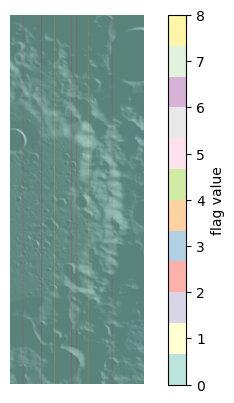

In [6]:
path_to_l1b = "./tutorial_data/m3g20090420t191718_l1b_rdn.fits"
with fits.open(path_to_l1b) as hdul: 
    rdn = hdul[0].data
    
band = 22 # 0-indexed 
plt.imshow(rdn[band], cmap='grey')
plt.imshow(flag[band], cmap='Set3', alpha=.6)
plt.colorbar(label='flag value')
plt.axis('off')
plt.show()

You can check for a specific flag by checking for that bit only, as below. Then you might want to set the corresponding pixels in the 
observation to NaN to more easily ignore them. 

In [7]:
# Flag definitions 
NAN = 1           # pixels set to NaN for being negative at L0 level (rollover)
BDE = 2           # pixels spectrally interpolated because flagged in the BDE
BLOCK_COL = 4     # pixels likely part of flashing ROIC background
BAD_COL = 8       # pixels part of a column offset from its neighbors in value
L2_DEPRECATED = 16  # bands flagged by the mission in L2 as deprecated

To get an array with _just_ one flag, use a bitwise AND and the flag value. For example, below we select only pixels that were spectrally interpolated (identified in the BDE map).

In [8]:
flag[band] & BDE

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(844, 304), dtype=uint8)

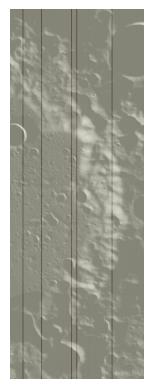

In [9]:
band = 22 # 0-indexed 
plt.imshow(rdn[band], cmap='grey')
plt.imshow(flag[band] & BDE, cmap='YlOrBr', alpha=.5)
plt.axis('off')
plt.show()

If you wanted to set all spectrally interpolated values in band 22 to NaN, you might do the following: 

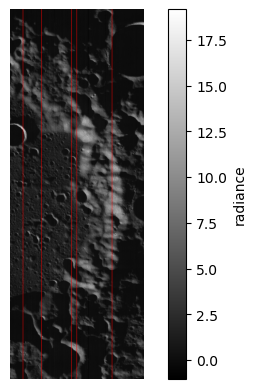

In [10]:
band = 22 
band_masked = np.where(flag[band] & BDE != 0, np.nan, rdn[band])   # turning flag mask into boolean array with != 0 

cmap = plt.colormaps.get_cmap('grey').copy()
cmap.set_bad(color='red')                     # set NaN values in the colormap to red 
plt.imshow(band_masked, cmap=cmap)
plt.colorbar(label='radiance')
plt.axis('off')
plt.show()

If you want to check for pixels where multiple flags are set at the same time, you can do the following:

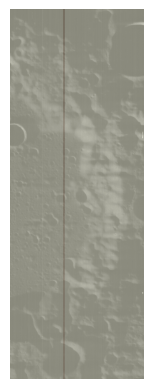

In [11]:
both_flags = BDE | BAD_COL

band = 0 # 0-indexed 
plt.imshow(rdn[band], cmap='grey')
plt.imshow((flag[band] & both_flags) == both_flags, cmap='YlOrBr', alpha=.5) # alternatively, you could do ((flags & BDE) != 0) & ((flags & BAD_COL) != 0)
plt.axis('off')
plt.show()

#### Spectrum with Flags

We can look at a sample spectrum and mark with vertical lines every band which is flagged. Notable this observation is relatively cool, so very few pixels are flagged. Warm observations (>155 K) will have signficantly more pixels flagged. 

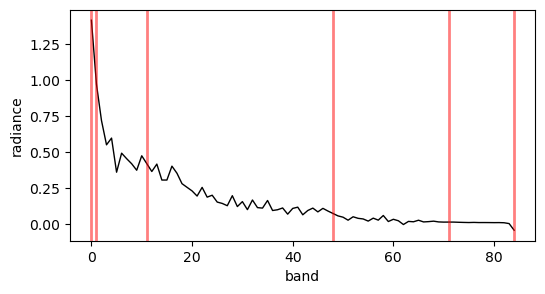

In [12]:
line = 200 
sample = 154 

spectrum = rdn[:, line , sample]
flagged = flag[:, line, sample] != 0              # here we are detecting ALL flags, not just spectrally interpolated ones 

plt.figure(figsize=(6, 3))
plt.plot(spectrum, lw=1, c='black')
for b in np.flatnonzero(flagged):
    plt.axvline(b, color='r', alpha=0.5, lw=2)    # adding vertical line at each flagged band 
plt.xlabel('band')
plt.ylabel('radiance')
plt.show()